<a href="https://colab.research.google.com/github/aishwaryaaramanathan/DL_Lab_241501011/blob/main/del_exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from torch.utils.data import DataLoader, TensorDataset

In [2]:
# Load and normalize data
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-airline-passengers.csv"
data = pd.read_csv(url).iloc[:, 1].values.reshape(-1, 1)

scaler = MinMaxScaler()
data = scaler.fit_transform(data).astype(np.float32)

In [3]:
# Create sequences
SEQ = 10
X = np.array([data[i:i+SEQ] for i in range(len(data)-SEQ)])
y = np.array([data[i+SEQ] for i in range(len(data)-SEQ)])

split = int(0.8 * len(X))
X_train, X_test = torch.tensor(X[:split]), torch.tensor(X[split:])
y_train, y_test = torch.tensor(y[:split]), torch.tensor(y[split:])

loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=16, shuffle=True
)

In [4]:
# Define models
class BiRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 32, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class FFNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(SEQ, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

In [5]:
# Train model
def train(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    loss_fn = nn.MSELoss()

    for epoch in range(100):
        for Xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(Xb), yb)
            loss.backward()
            optimizer.step()

        if (epoch+1) % 20 == 0:
            print(f"Epoch {epoch+1}, Loss: {loss.item():.5f}")

    return model

In [6]:
# Train and predict
birnn = train(BiRNN())
ffnn = train(FFNN())

with torch.no_grad():
    pred_birnn = birnn(X_test).numpy()
    pred_ffnn = ffnn(X_test).numpy()

Epoch 20, Loss: 0.00540
Epoch 40, Loss: 0.00156
Epoch 60, Loss: 0.00146
Epoch 80, Loss: 0.00508
Epoch 100, Loss: 0.00318
Epoch 20, Loss: 0.00413
Epoch 40, Loss: 0.00112
Epoch 60, Loss: 0.00146
Epoch 80, Loss: 0.00126
Epoch 100, Loss: 0.00093


In [7]:
# Convert predictions to original scale
actual = scaler.inverse_transform(y_test.numpy())
pred_birnn = scaler.inverse_transform(pred_birnn)
pred_ffnn = scaler.inverse_transform(pred_ffnn)

In [8]:
# Compare MSE
print("BiRNN MSE:", mean_squared_error(actual, pred_birnn))
print("FFNN MSE:", mean_squared_error(actual, pred_ffnn))

BiRNN MSE: 1680.1885986328125
FFNN MSE: 1505.49560546875


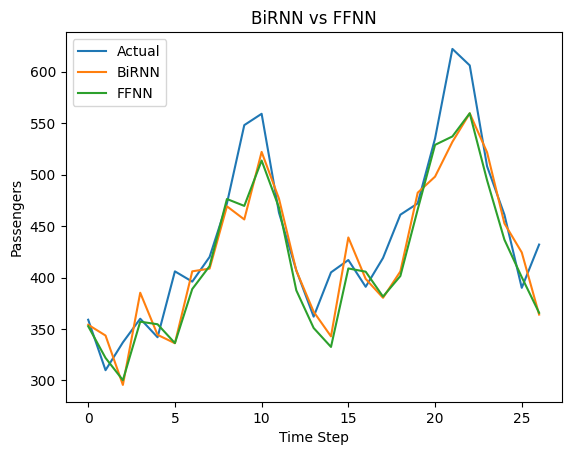

In [9]:
# Plot predictions
plt.plot(actual, label="Actual")
plt.plot(pred_birnn, label="BiRNN")
plt.plot(pred_ffnn, label="FFNN")
plt.xlabel("Time Step")
plt.ylabel("Passengers")
plt.title("BiRNN vs FFNN")
plt.legend()
plt.show()